In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
import zipfile
with zipfile.ZipFile('/content/AB_NYC_2019.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')


In [13]:
df = pd.read_csv('/content/AB_NYC_2019.csv')

In [14]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [15]:
# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [16]:
# Check data types and missing values
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_revie

In [58]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [17]:
# Separate numerical and categorical columns
numerical_columns = df.select_dtypes(include=['number']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()


In [18]:
print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [19]:
print("\nCategorical Columns:")
print(categorical_columns)


Categorical Columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [21]:
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


In [23]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("\nMissing Value Percentages:")
print(missing_percentage)


Missing Value Percentages:
id                                 0.000000
name                               0.032723
host_id                            0.000000
host_name                          0.042949
neighbourhood_group                0.000000
neighbourhood                      0.000000
latitude                           0.000000
longitude                          0.000000
room_type                          0.000000
price                              0.000000
minimum_nights                     0.000000
number_of_reviews                  0.000000
last_review                       20.558339
reviews_per_month                 20.558339
calculated_host_listings_count     0.000000
availability_365                   0.000000
dtype: float64


In [24]:
# Display columns with missing values
print("Columns with Missing Values:")
print(missing_values[missing_values > 0])

Columns with Missing Values:
name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64


In [25]:
# Check the number of reviews for rows with missing reviews_per_month
print(df.loc[df['reviews_per_month'].isnull(), 'number_of_reviews'].value_counts())

number_of_reviews
0    10052
Name: count, dtype: int64


In [26]:
# Drop columns that are not useful for the model
df = df.drop(columns=['last_review', 'name', 'host_name', 'id', 'host_id'],
             errors='ignore')

In [27]:
# Replace missing reviews_per_month with 0
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [28]:
# Check missing values after cleaning
print(df.isnull().sum())

neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

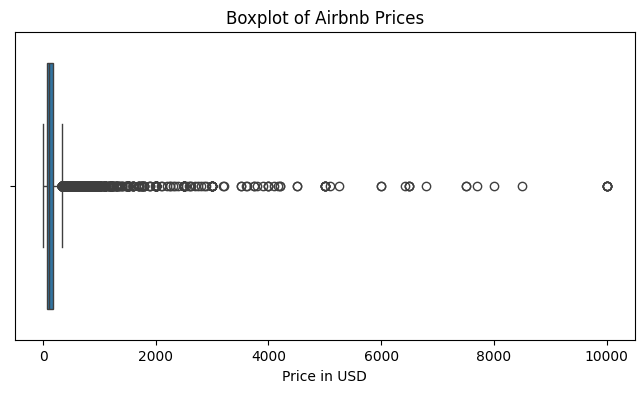

In [30]:
# Boxplot for Airbnb prices
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['price'])
plt.title('Boxplot of Airbnb Prices')
plt.xlabel('Price in USD')
plt.show()

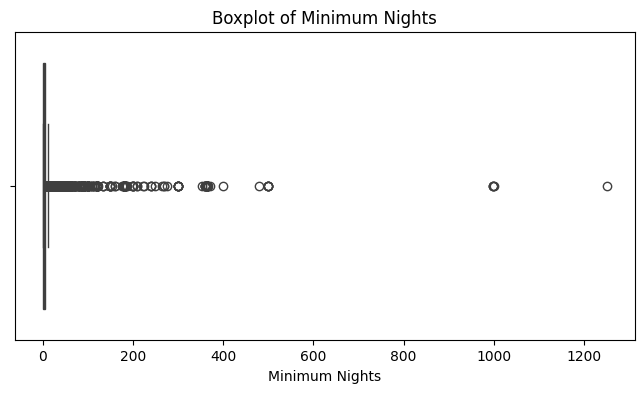

In [31]:
# Boxplot for minimum nights
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['minimum_nights'])
plt.title('Boxplot of Minimum Nights')
plt.xlabel('Minimum Nights')
plt.show()

In [32]:
# Remove extreme Airbnb prices and unusually long stays
# Find the 95th percentile of price
price_95 = df['price'].quantile(0.95)


In [33]:
# Record the number of rows before cleaning
before_cleaning = len(df)

In [34]:
# Keep prices at or below the 95th percentile
# Remove listings with minimum stays of 365 nights or more
df = df[(df['price'] <= price_95) & (df['minimum_nights'] < 365)].copy()

In [35]:
# Display the results
print("95th Percentile Price:", price_95)
print("Rows before cleaning:", before_cleaning)
print("Rows after cleaning:", len(df))
print("Rows removed:", before_cleaning - len(df))

95th Percentile Price: 355.0
Rows before cleaning: 48895
Rows after cleaning: 46417
Rows removed: 2478


In [36]:
# Remove neighbourhood column
df = df.drop(columns=['neighbourhood'], errors='ignore')

In [37]:
# Check remaining columns
print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [38]:
# Convert categorical columns into numerical columns
df = pd.get_dummies(df,columns=['neighbourhood_group', 'room_type'],drop_first=True,dtype=int)

In [39]:
# Display the new columns
print("Columns after encoding:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

Columns after encoding:
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']

First 5 rows:
   latitude  longitude  price  minimum_nights  number_of_reviews  \
0  40.64749  -73.97237    149               1                  9   
1  40.75362  -73.98377    225               1                 45   
2  40.80902  -73.94190    150               3                  0   
3  40.68514  -73.95976     89               1                270   
4  40.79851  -73.94399     80              10                  9   

   reviews_per_month  calculated_host_listings_count  availability_365  \
0               0.21                               6               365   
1               0.38                               2               355  

In [40]:
#Separate Features (X) and Target (y)
# Remove the target column from the input features
X = df.drop(columns=['price'])


In [41]:
# Convert any remaining categorical columns into numbers
X = pd.get_dummies(X, drop_first=True)

In [42]:
# Target variable: the price we want to predict
y = df['price']

In [43]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (46417, 13)
Target shape: (46417,)


In [44]:
from sklearn.model_selection import train_test_split
# Split data: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (37133, 13)
Testing features: (9284, 13)
Training target: (37133,)
Testing target: (9284,)


In [48]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()


In [49]:
# Train the model
model.fit(X_train, y_train)

LinearRegression()

In [50]:
# Predict prices for the test data
y_pred = model.predict(X_test)
print("Predictions:", y_pred[:10])

Predictions: [ 76.07714099 154.08859994  84.77060267  70.7688319   64.87323
  71.15250699  53.69114366 152.38663195 132.51928334  63.4354913 ]


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))

Mean Absolute Error (MAE): 37.97
Mean Squared Error (MSE): 2725.05
Root Mean Squared Error (RMSE): 52.2
R² Score: 0.4716


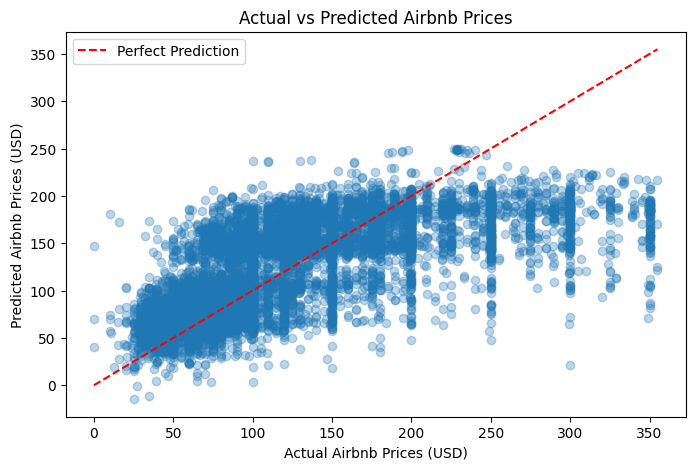

In [56]:
#Compare Actual vs Predicted Prices
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

# Add the diagonal line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Airbnb Prices (USD)")
plt.ylabel("Predicted Airbnb Prices (USD)")
plt.title("Actual vs Predicted Airbnb Prices")
plt.legend()
plt.show()

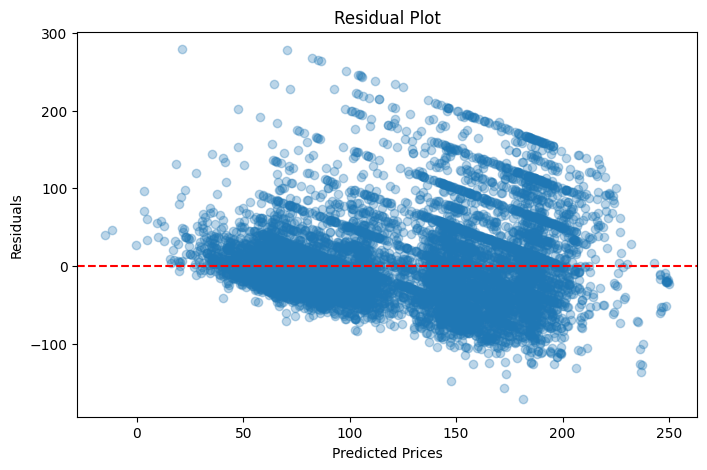

In [53]:
#Residual Plot
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [57]:
# Compare prediction errors for different price ranges
results = pd.DataFrame({'Actual Price': y_test,'Predicted Price': y_pred})
results['Absolute Error'] = abs(
    results['Actual Price'] - results['Predicted Price'])
results['Price Category'] = pd.cut(
    results['Actual Price'],
    bins=[-1, 50, 100, 200, float('inf')],
    labels=['Cheap ($0-$50)', '$51-$100', '$101-$200', 'Above $200'])
print("Average prediction error by price category:")
print(results.groupby('Price Category', observed=True)['Absolute Error'].mean().round(2))

Average prediction error by price category:
Price Category
Cheap ($0-$50)    27.74
$51-$100          29.13
$101-$200         31.91
Above $200        94.99
Name: Absolute Error, dtype: float64


In [54]:
#Check Model Evaluation Results
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 37.97
Mean Squared Error (MSE): 2725.05
Root Mean Squared Error (RMSE): 52.2
R2 Score: 0.4716


#**Conclusion**

In this project, Linear Regression was used to predict Airbnb prices in New York City using the AB_NYC_2019 dataset. The model was trained using 80% of the data and tested using the remaining 20%.

The model achieved a Mean Absolute Error (MAE) of 37.97, a Root Mean Squared Error (RMSE) of 52.20, and an R² score of 0.4716. These results indicate that the model captures some of the variation in Airbnb prices, but its predictive performance can be improved.

Future improvements could include better feature selection, additional data preprocessing, and testing other regression algorithms.
### Model Performance on Cheap vs. Expensive Listings

The model performs better on cheaper Airbnb listings. The average absolute prediction error is $27.74 for listings priced at $50 or below, compared with $94.99 for listings priced above $200. This suggests that the model has more difficulty predicting expensive listings. The larger errors may occur because expensive listings have more varied characteristics that a simple Linear Regression model cannot fully capture.